In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('../src')

from pathlib import Path
import polars as pl
from joblib import load
from tqdm.notebook import tqdm
from matplotlib import pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

from training import prepare_features_for_classification, prepare_predictions_dataframe, make_predictions

# Performing inference

The following performs inference on the feature parquets and saves the predictions results in the corresponding `classifications` folder

In [2]:
%%time

plato_data_directory = Path('/STER/mamsie/tess/TIC/plato_fov/')
training_set = "training_set_v13"

df_training_set = pl.read_parquet(Path('../data') / f'{training_set}.parquet').select(['path', 'label', 'GaiaID', 'sector'])

model_path = Path('../results/classifications') / f"{training_set}_reg"
feature_config = load(model_path / 'feature_config.pkl')
clf = load(model_path / 'model_xgboost.pkl')
le = load(model_path / 'label_encoder.pkl')

CPU times: user 426 ms, sys: 33.7 ms, total: 460 ms
Wall time: 118 ms


In [3]:
def predict(features_parquet_path: Path) -> pl.DataFrame:
    df_inference_features = pl.read_parquet(features_parquet_path)
    df_inference_features, df_dropped = prepare_features_for_classification(df_inference_features, **feature_config)
    paths = df_inference_features['path'].to_numpy()
    X = df_inference_features.drop(['path']).to_numpy()
    return prepare_predictions_dataframe(clf, le, X, paths, drop_nans=True).with_columns(
        pl.col('path').str.split('-').list.get(3).alias('sector').str.split('s').list.get(-1).cast(pl.Int64),
        pl.col('path').str.split('-').list.get(2).cast(pl.Int64).alias('GaiaDR3')
    )

predict('../results/features/s0001/part-000000.parquet')

path,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENTAL,RRLYR_CEPH,SOLARLIKE,best_class,entropy,best_proba,sector,GaiaDR3
str,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,i64,i64
"""/STER/mamsie/tess/TIC/plato_fo…",0.004371,0.001021,0.969709,0.000017,0.024808,0.000033,0.000043,"""ECLIPSE""",0.078759,0.969709,1,4674486828368062336
"""/STER/mamsie/tess/TIC/plato_fo…",0.00078,0.034072,0.087807,0.00036,0.779193,0.097317,0.000471,"""INSTRUMENTAL""",0.391547,0.779193,1,4674480987212044416
"""/STER/mamsie/tess/TIC/plato_fo…",0.000563,0.00204,0.156682,0.000639,0.834021,0.003228,0.002826,"""INSTRUMENTAL""",0.256148,0.834021,1,4674487000166276480
"""/STER/mamsie/tess/TIC/plato_fo…",0.00012,0.000032,0.024342,0.000041,0.975465,5.0321e-7,1.8019e-7,"""INSTRUMENTAL""",0.059873,0.975465,1,4674485969374108672
"""/STER/mamsie/tess/TIC/plato_fo…",0.001256,0.000188,0.994891,4.0174e-7,0.003229,0.000428,0.000007,"""ECLIPSE""",0.019032,0.994891,1,4674487515562352256
…,…,…,…,…,…,…,…,…,…,…,…,…
"""/STER/mamsie/tess/TIC/plato_fo…",0.000041,0.000014,0.000047,0.000002,0.999145,0.000003,0.00075,"""INSTRUMENTAL""",0.003771,0.999145,1,4657237071546388480
"""/STER/mamsie/tess/TIC/plato_fo…",0.000008,0.000011,0.001042,0.000003,0.994853,0.000013,0.00407,"""INSTRUMENTAL""",0.018031,0.994853,1,4657231500951014400
"""/STER/mamsie/tess/TIC/plato_fo…",0.087794,0.000229,0.596037,0.000018,0.315772,0.00002,0.000129,"""ECLIPSE""",0.457109,0.596037,1,4657231500917236992


In [4]:
for sector_path in tqdm(sorted(Path('../results/features/').glob('s*'))):
    save_path = Path(f'../results/classifications/{sector_path.name}/')
    if (save_path / 'predictions.parquet').exists():
        continue
    df_pred = predict(sector_path)
    #display(df_pred.head())    
    save_path.mkdir(parents=True, exist_ok=True)
    df_pred.write_parquet(save_path / 'predictions.parquet')

  0%|          | 0/26 [00:00<?, ?it/s]

Extra feature folders that were requested a posteriori

In [26]:
save_path = Path(f'../results/classifications/s_extra_data')
df_pred = predict('../results/features/extra_data')
save_path.mkdir(parents=True, exist_ok=True)
df_pred.write_parquet(save_path / 'predictions.parquet')

In [6]:
save_path = Path(f'../results/classifications/SDSS')
df_pred = predict('../results/features/SDSS/part*.parquet')
save_path.mkdir(parents=True, exist_ok=True)
df_pred.write_parquet(save_path / 'predictions.parquet')

In [ ]:
save_path = Path(f'../results/classifications/downsampled_lc')
df_pred = predict('../results/features/downsampled_lc/')
   save_path.mkdir(parents=True, exist_ok=True)
df_pred.write_parquet(save_path / 'predictions.parquet')

# Joining with neural net predictions

In [10]:
labels = le.classes_.copy()
labels[5] = 'JUNK'
class_mapper = {k: name for k, name in enumerate(le.classes_)}

In [11]:
df_s1_nnet = []
for file in sorted(Path('/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/').rglob('*.csv')):
    print(file)
    df_s1_nnet.append(pl.read_csv(file))
df_s1_nnet = pl.concat(df_s1_nnet)    
df_s1_nnet = df_s1_nnet.with_columns(
    probs = pl.col("probabilities").str.json_decode(dtype=pl.Struct([pl.Field(name, pl.Float64) for name in labels]))
).with_columns(
    best_nnet_class = pl.concat_list([pl.col("probs").struct.field(k) for k in labels]).list.arg_max(),
    best_nnet_proba = pl.concat_list([pl.col("probs").struct.field(k) for k in labels]).list.max()
).with_columns(
    pl.col('best_nnet_class').cast(pl.String).replace(class_mapper)
).drop('probs')

/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_0/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_1/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_10/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_11/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_12/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_13/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_14/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_15/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_16/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_17/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_2/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_3/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/sh

In [13]:
df_all_preds = pl.read_parquet(
    '../results/classifications/s*/*.parquet', columns=['path', 'best_rf_class', 'best_rf_proba', 'rf_entropy']
).join(
    pl.read_parquet('../results/features/s*/*.parquet', columns=['path', 'ls_frequency_fundamental', 'ls_amplitude_fundamental', 'num_negative_fluxes']),
    on='path'
)
df_all_preds.shape
    
df_join = df_s1_nnet.join(df_all_preds.rename({'path':'FilePath'}), on='FilePath')
df_join.head()

tic,FilePath,GaiaDR3,TIC,RA,DEC,f1,A1,probabilities,best_nnet_class,best_nnet_proba,best_rf_class,best_rf_proba,rf_entropy,ls_frequency_fundamental,ls_amplitude_fundamental,num_negative_fluxes
i64,str,i64,i64,f64,f64,f64,f64,str,str,f64,str,f64,f64,f64,f64,i64
32034215,"""/STER/mamsie/tess/TIC/plato_fo…",4667736441152277504,32034215,56.355286,-68.197844,0.941408,8.613914,"""{""APERIODIC"": 0.00037, ""CONTAC…","""INSTRUMENT/JUNK""",0.927948,"""INSTRUMENT/JUNK""",0.943522,0.147054,0.939871,0.099783,0
32032791,"""/STER/mamsie/tess/TIC/plato_fo…",4667739984501242752,32032791,56.227544,-68.122165,0.998892,5.753028,"""{""APERIODIC"": 0.000446, ""CONTA…","""INSTRUMENT/JUNK""",0.988857,"""INSTRUMENT/JUNK""",0.988,0.039346,0.996637,0.084266,0
32034188,"""/STER/mamsie/tess/TIC/plato_fo…",4667738369593543168,32034188,56.366829,-68.120236,0.998892,0.970102,"""{""APERIODIC"": 0.00047, ""CONTAC…","""INSTRUMENT/JUNK""",0.904064,"""INSTRUMENT/JUNK""",0.99779,0.009003,0.994481,0.069241,0
32034197,"""/STER/mamsie/tess/TIC/plato_fo…",4667736857765058304,32034197,56.339548,-68.153965,2.012056,0.416163,"""{""APERIODIC"": 0.005222, ""CONTA…","""ECLIPSE""",0.727993,"""INSTRUMENT/JUNK""",0.949762,0.128071,2.006926,0.018458,0
32034202,"""/STER/mamsie/tess/TIC/plato_fo…",4667736582887153664,32034202,56.378098,-68.16696,2.00487,4.775729,"""{""APERIODIC"": 0.000545, ""CONTA…","""INSTRUMENT/JUNK""",0.970041,"""INSTRUMENT/JUNK""",0.534555,0.55104,2.002615,0.126888,0


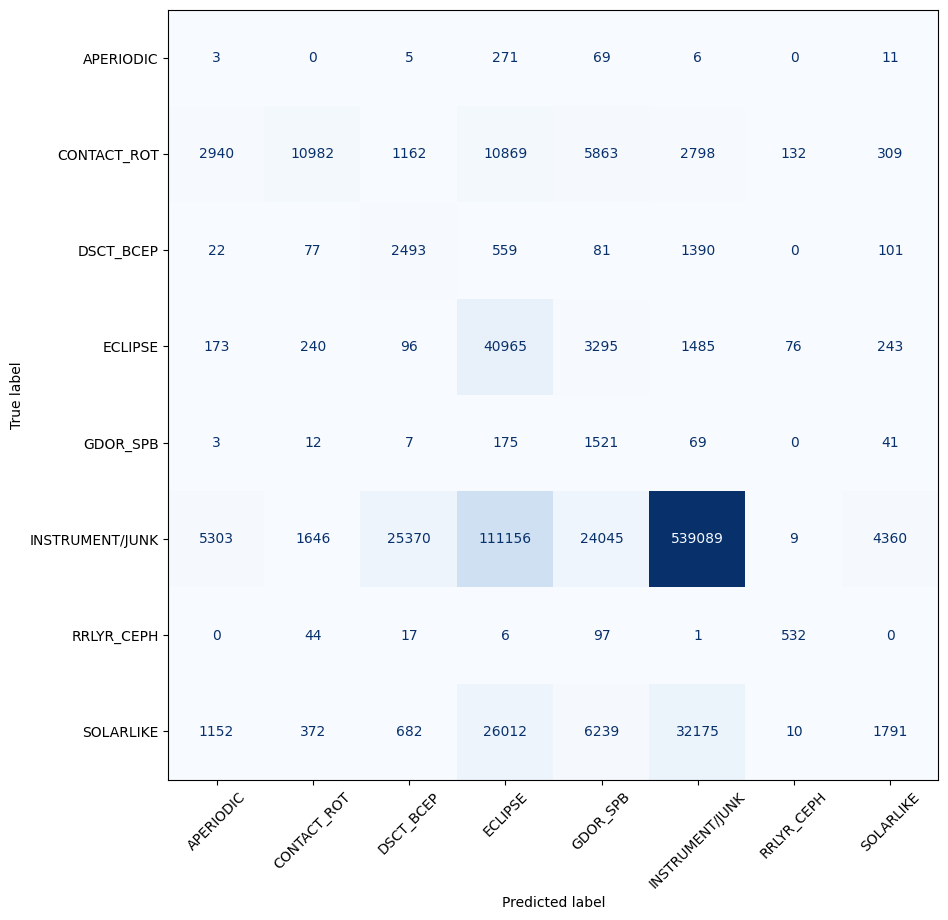

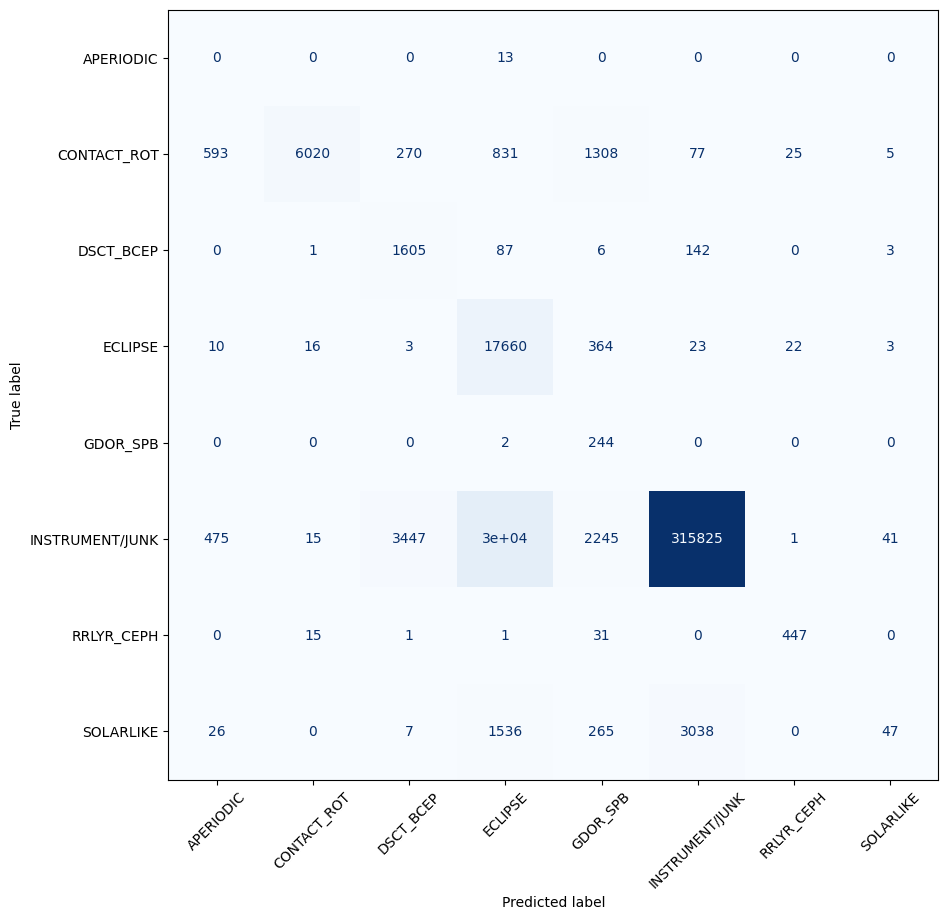

In [17]:
only_high_conf = pl.col('best_nnet_proba').gt(0.75) & pl.col('best_rf_proba').gt(0.75)

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(
    y_true=df_join['best_rf_class'].to_numpy(), 
    y_pred=df_join['best_nnet_class'].to_numpy(), 
    ax=ax, cmap=plt.cm.Blues, xticks_rotation=45, colorbar=False, 
)

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(
    y_true=df_join.filter(only_high_conf)['best_rf_class'].to_numpy(), 
    y_pred=df_join.filter(only_high_conf)['best_nnet_class'].to_numpy(), 
    ax=ax, cmap=plt.cm.Blues, xticks_rotation=45, colorbar=False
)

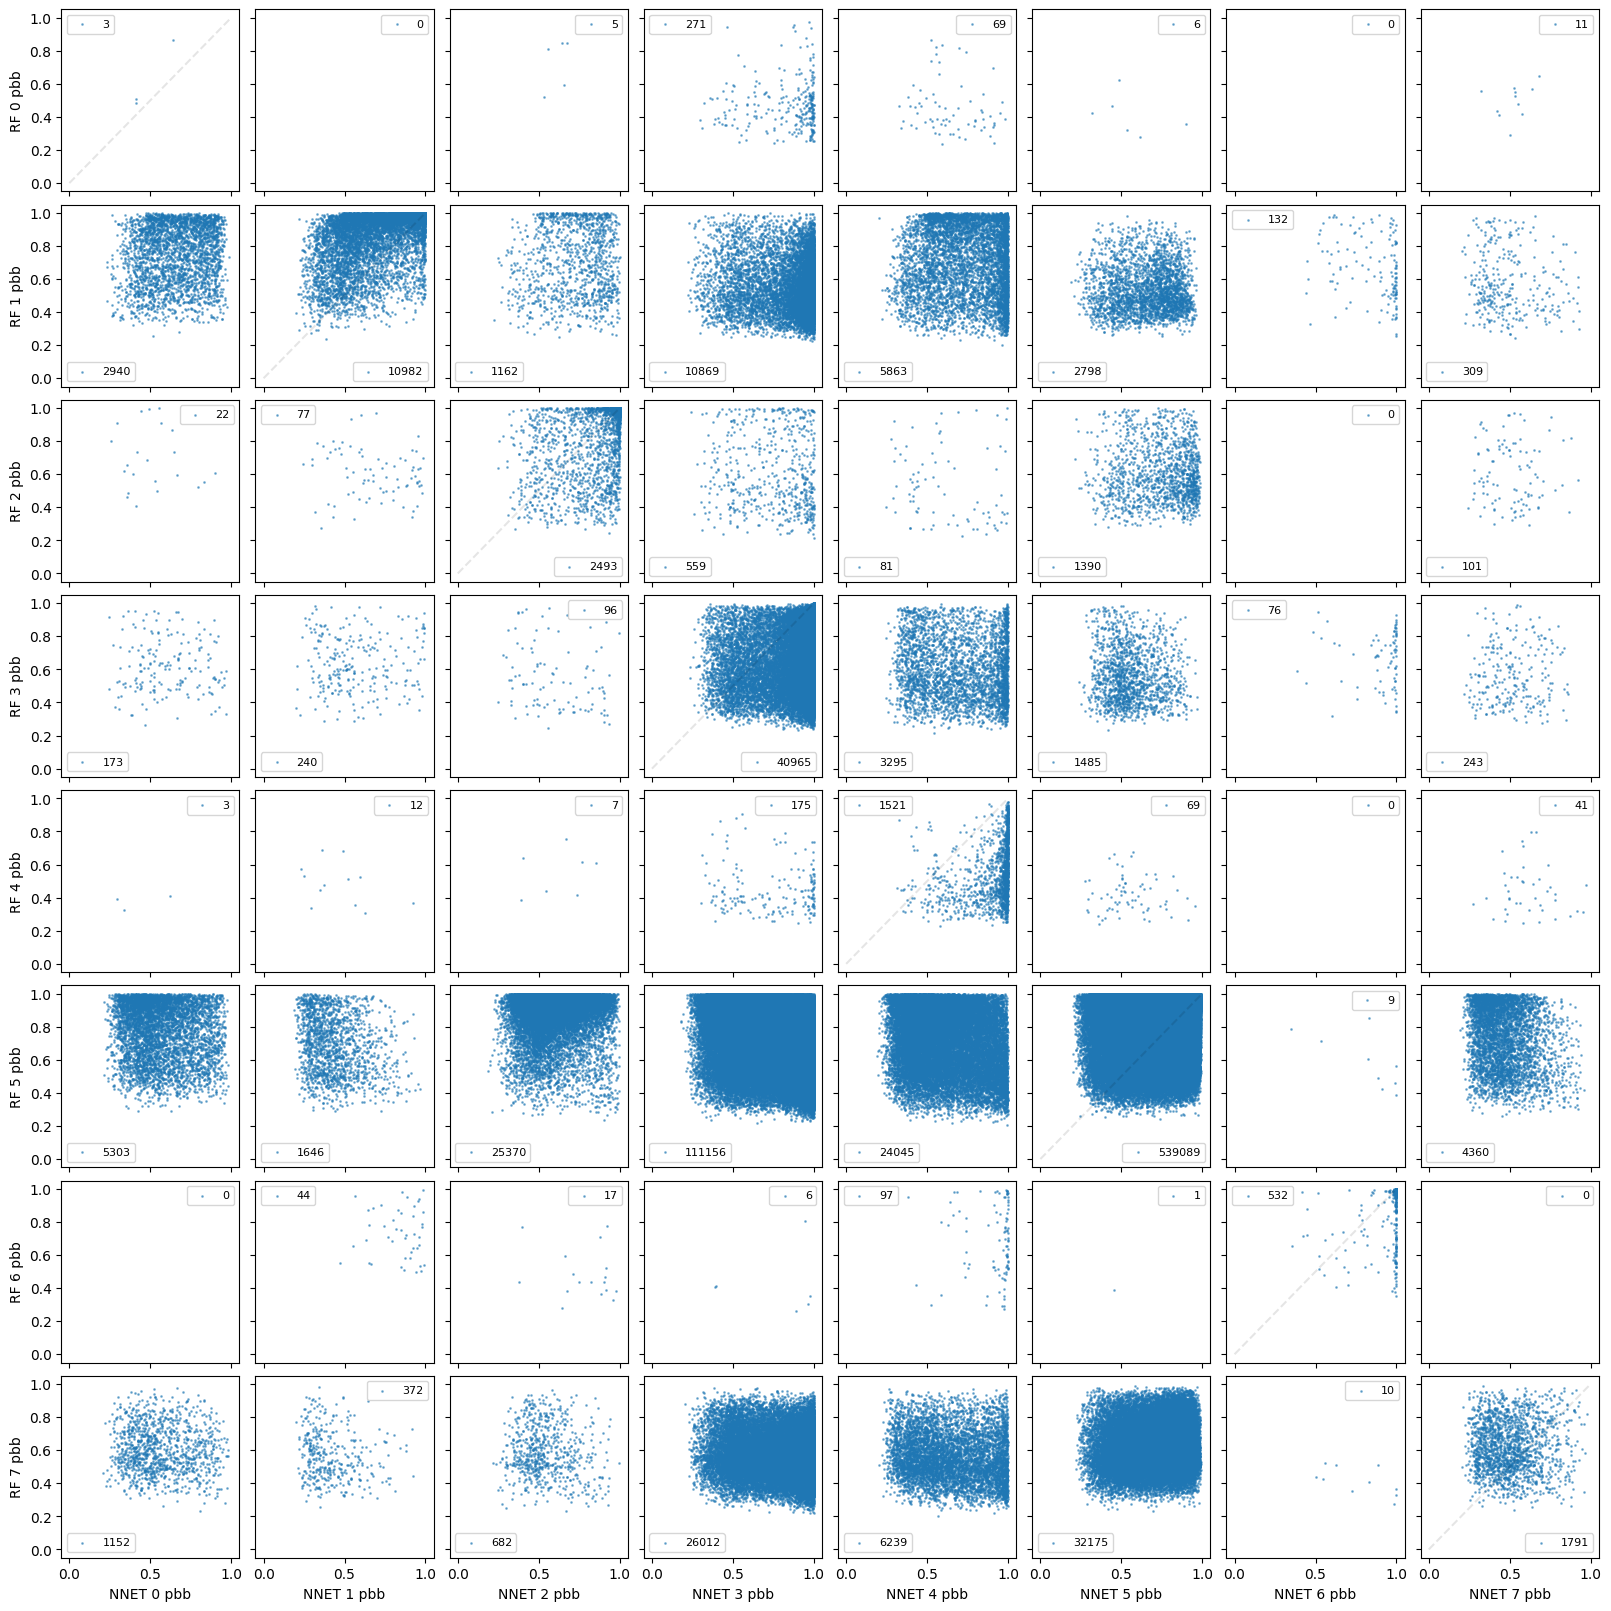

In [18]:
fig, axs = plt.subplots(len(le.classes_), len(le.classes_), figsize=(16, 16), constrained_layout=True, sharex=True, sharey=True)
for i, rf_class in enumerate(le.classes_):
    for j, nnet_class in enumerate(le.classes_):
        selection = df_join.filter(pl.col('best_rf_class').eq(rf_class) & pl.col('best_nnet_class').eq(nnet_class))
        axs[i, j].scatter(selection['best_nnet_proba'].to_numpy(), selection['best_rf_proba'].to_numpy(), alpha=0.5, s=1, label=len(selection))
        axs[i, j].legend(fontsize=8)
        if i == j:
            axs[i, i].plot([0, 1], [0, 1], ls='--', alpha=0.1, c='k')

for i, rf_class in enumerate(clf.classes_):
    axs[i, 0].set_ylabel(f'RF {rf_class} pbb')
for j, nnet_class in enumerate(clf.classes_):
    axs[-1, j].set_xlabel(f'NNET {nnet_class} pbb')

Text(0, 0.5, 'RF INSTRUMENT/JUNK probability')

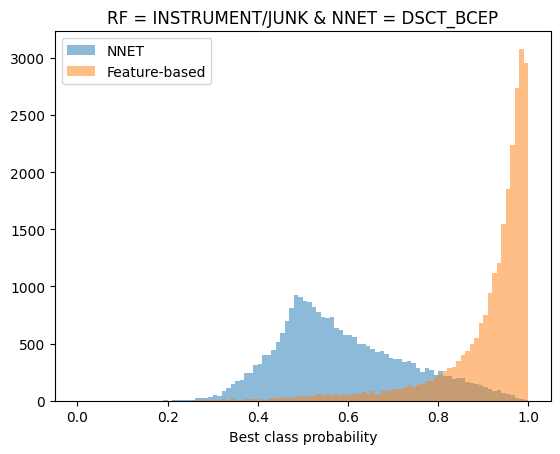

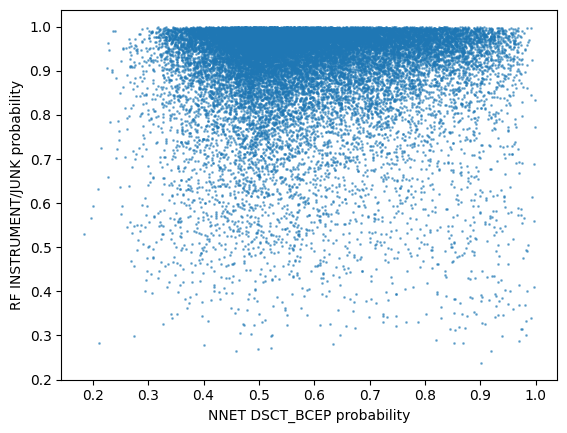

In [19]:
rf_class = 'INSTRUMENT/JUNK'
nnet_class = 'DSCT_BCEP'
disagreements = df_join.filter(
    pl.col('best_rf_class').eq(rf_class) & pl.col('best_nnet_class').eq(nnet_class)
#).filter(
#    pl.col('best_rf_proba').gt(0.75) & pl.col('best_nnet_proba').gt(0.9)
)
fig, ax = plt.subplots()
ax.hist(disagreements['best_nnet_proba'].to_numpy(), range=(0, 1), bins=100, label='NNET', alpha=0.5)
ax.hist(disagreements['best_rf_proba'].to_numpy(), range=(0, 1), bins=100, label='Feature-based', alpha=0.5)
ax.set_xlabel('Best class probability')
ax.legend()
ax.set_title(f'RF = {rf_class} & NNET = {nnet_class}')

fig, ax = plt.subplots()
ax.scatter(disagreements['best_nnet_proba'].to_numpy(), disagreements['best_rf_proba'].to_numpy(), alpha=0.5, s=1)
ax.set_xlabel(f'NNET {nnet_class} probability')
ax.set_ylabel(f'RF {rf_class} probability')

402


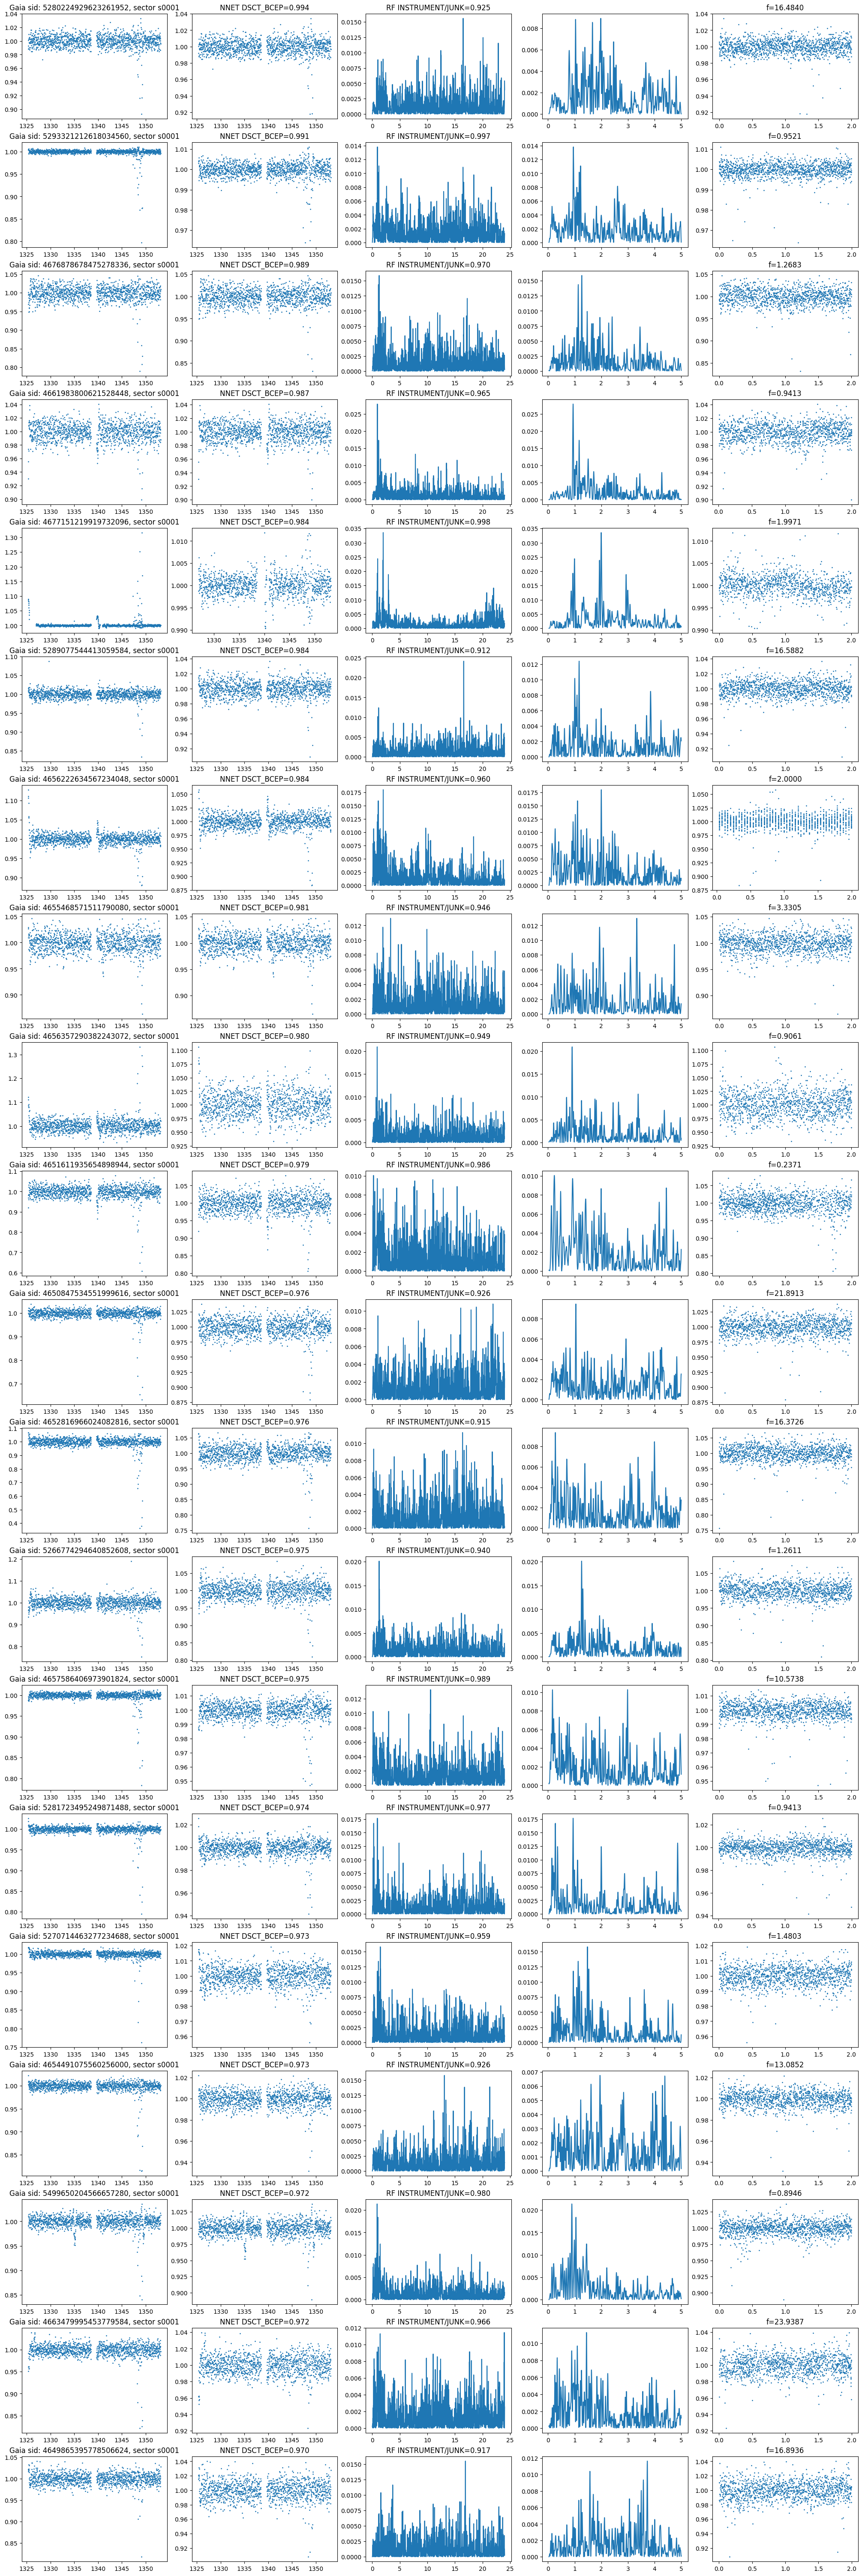

In [23]:
import numpy as np
from light_curves import read_fits_lc, preprocess_lc
from frequency_domain_features import compute_lombscargle_periodogram


disagreements = df_join.filter(
    pl.col('best_rf_class').eq(rf_class) & pl.col('best_nnet_class').eq(nnet_class)
).filter(
    pl.col('best_rf_proba').gt(0.9) & pl.col('best_nnet_proba').gt(0.9)
).sort('best_nnet_proba', descending=True)
print(disagreements.height)
sub_df = disagreements.head(20)
n_plots = sub_df.height
fig, axs = plt.subplots(max(2, n_plots), 5, figsize=(20, 3*n_plots), constrained_layout=True, sharex=False)
for row, ax in zip(sub_df.iter_rows(named=True), axs):
    path_, rf_proba, nnet_proba = row['FilePath'], row['best_rf_proba'], row['best_nnet_proba']
    sid, sector = path_.split('-')[2:4]
    ax[0].set_title(f"Gaia sid: {sid}, sector {sector}")
    ax[1].set_title(f"NNET {nnet_class}={nnet_proba:0.3f}")
    ax[2].set_title(f"RF {rf_class}={rf_proba:0.3f}")
    time, flux, sector = read_fits_lc(path_)
    ax[0].scatter(time, flux, s=1)
    time_pre, flux_pre = preprocess_lc(time, flux, sector)
    ax[1].scatter(time_pre, flux_pre, s=1)
    freq, ampl, _ = compute_lombscargle_periodogram(time_pre, flux_pre)
    best_freq = freq[np.argmax(ampl)]
    ax[2].plot(freq, ampl)
    ax[3].plot(freq[freq<5], ampl[freq<5])
    ax[4].set_title(f"f={best_freq:0.4f}")
    ax[4].scatter(np.mod(time_pre, 2/best_freq)*best_freq, flux_pre, s=1)

In [ ]:
# disagreements.write_parquet('../results/INSTRUMENT_nnet_predicted_as_DSCT.parquet')